# 1. Data Inputs & Basic Checks

In [111]:
import pandas as pd
pd.plotting.register_matplotlib_converters()
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
print("Setup Complete")

Setup Complete


## 1.1 Load data


In [112]:
beneficiary = pd.read_csv("/kaggle/input/datasets/sophiali/datahealthcare/Train_Beneficiarydata-1542865627584.csv/Train_Beneficiarydata-1542865627584.csv")
inpatient = pd.read_csv("/kaggle/input/datasets/sophiali/datahealthcare/Train_Inpatientdata-1542865627584.csv/Train_Inpatientdata-1542865627584.csv")
outpatient = pd.read_csv("/kaggle/input/datasets/sophiali/datahealthcare/Train_Outpatientdata-1542865627584.csv/Train_Outpatientdata-1542865627584.csv")
train = pd.read_csv("/kaggle/input/datasets/sophiali/datahealthcare/Train-1542865627584.csv")

In [113]:
print("{db_name} dataset has {r} rows and {c} columns".format(db_name = "beneficiary", r = beneficiary.shape[0], c = beneficiary.shape[1]))
print("{db_name} dataset has {r} rows and {c} columns".format(db_name = "inpatient", r = inpatient.shape[0], c = inpatient.shape[1]))
print("{db_name} dataset has {r} rows and {c} columns".format(db_name = "outpatient", r = outpatient.shape[0], c = outpatient.shape[1]))
print("{db_name} dataset has {r} rows and {c} columns".format(db_name = "train", r = train.shape[0], c = train.shape[1]))

beneficiary dataset has 138556 rows and 25 columns
inpatient dataset has 40474 rows and 30 columns
outpatient dataset has 517737 rows and 27 columns
train dataset has 5410 rows and 2 columns


In [114]:
beneficiary.head(3)

,BeneID,DOB,DOD,Gender,Race,RenalDiseaseIndicator,State,County,NoOfMonths_PartACov,NoOfMonths_PartBCov,...,ChronicCond_Depression,ChronicCond_Diabetes,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt
0,BENE11001,1943-01-01,NaN,1,1,0,39,230,12,12,...,1,1,1,2,1,1,36000,3204,60,70
1,BENE11002,1936-09-01,NaN,2,1,0,39,280,12,12,...,2,2,2,2,2,2,0,0,30,50
2,BENE11003,1936-08-01,NaN,1,1,0,52,590,12,12,...,2,2,1,2,2,2,0,0,90,40


In [115]:
inpatient.head(3)

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,...,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6
0,BENE11001,CLM46614,2009-04-12,2009-04-18,PRV55912,26000,PHY390922,NaN,NaN,2009-04-12,...,2724,19889,5849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BENE11001,CLM66048,2009-08-31,2009-09-02,PRV55907,5000,PHY318495,PHY318495,NaN,2009-08-31,...,NaN,NaN,NaN,NaN,7092.0,NaN,NaN,NaN,NaN,NaN
2,BENE11001,CLM68358,2009-09-17,2009-09-20,PRV56046,5000,PHY372395,NaN,PHY324689,2009-09-17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [116]:
outpatient.head(3)

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,ClmDiagnosisCode_1,...,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,DeductibleAmtPaid,ClmAdmitDiagnosisCode
0,BENE11002,CLM624349,2009-10-11,2009-10-11,PRV56011,30,PHY326117,NaN,NaN,78943,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,56409
1,BENE11003,CLM189947,2009-02-12,2009-02-12,PRV57610,80,PHY362868,NaN,NaN,6115,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,79380
2,BENE11003,CLM438021,2009-06-27,2009-06-27,PRV57595,10,PHY328821,NaN,NaN,2723,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN


In [117]:
train.head(3)

,Provider,PotentialFraud
0,PRV51001,No
1,PRV51003,Yes
2,PRV51004,No


## 1.2 Key and join checks
Check result:
1. Primary key check: The primary keys are unique in the 4 tables. no duplicated values
2. Primary key check: There is no overlapping of claim ID between inpatient claim IDs and outpatient claim IDs
3. Foreign key check: Every claim's BeneID (in inpatient and outpatient) exists in Beneficiary
4. Foreign key check: The providers from inpatient and outpatient files are fully matched with the providers in train file.

### 1.2.1 The primary keys are unique in the 4 tables. no duplicated values

In [118]:
# check if the primary keys in each table are unique
print("How many duplicated values for primary key BeneID in beneficiary table? {} row(s)".format(beneficiary.BeneID.duplicated().sum()))
print("How many duplicated values for primary key ClaimID in inpatient table? {} row(s)".format(inpatient.ClaimID.duplicated().sum()))
print("How many duplicated values for primary key ClaimID in outpatient table? {} row(s)".format(outpatient.ClaimID.duplicated().sum()))
print("How many duplicated values for primary key Provider in train table? {} row(s)".format(train.Provider.duplicated().sum()))

How many duplicated values for primary key BeneID in beneficiary table? 0 row(s)
How many duplicated values for primary key ClaimID in inpatient table? 0 row(s)
How many duplicated values for primary key ClaimID in outpatient table? 0 row(s)
How many duplicated values for primary key Provider in train table? 0 row(s)


### 1.2.2 There is no overlapping of claim ID between inpatient claim IDs and outpatient claim IDs

In [119]:
# check if any overlapped claim IDs in inpatient and outpatient tables
pd.concat([inpatient.ClaimID, outpatient.ClaimID]).duplicated().sum()

np.int64(0)

### 1.2.3 Every claim BeneID (in inpatient and outpatient) exists in Beneficiary

In [120]:
# compute the resulting number of distinct values after the union of inpatient and outpatient bene IDs inner join with Bene ID table
pd.concat([inpatient.BeneID, outpatient.BeneID]).isin(beneficiary.BeneID).all()

np.True_

### 1.2.4 The providers from inpatient and outpatient files are fully matched with the providers in train file.

In [121]:
inpatient_providers = inpatient.groupby('Provider').ClaimID.nunique().reset_index().rename(columns={'ClaimID':'ClaimCount'})
outpatient_providers = outpatient.groupby('Provider').ClaimID.nunique().reset_index().rename(columns={'ClaimID':'ClaimCount'})
total_providers = inpatient_providers.merge(outpatient_providers, on = 'Provider', how = 'outer', suffixes = ('Inpatient', 'Outpatient'))

In [122]:
total_providers.shape

(5410, 3)

In [123]:
train.shape

(5410, 2)

In [124]:
total_providers_w_fraud = total_providers.merge(train, on = 'Provider', how = 'outer')
total_providers_w_fraud.shape

(5410, 4)

In [125]:
print("out of total {0} providers, {1} are flagged as potential fraud, {2} are not"
      .format(total_providers_w_fraud.shape[0]
              , total_providers_w_fraud.groupby('PotentialFraud').Provider.count().Yes
              , total_providers_w_fraud.groupby('PotentialFraud').Provider.count().No))

out of total 5410 providers, 506 are flagged as potential fraud, 4904 are not


## 1.3 Beneficiary checks
1. Check all columns for NA
2. Check amount columns: IPAnnualReimbursementAmt, IPAnnualDeductibleAmt, OPAnnualReimbursementAmt, OPAnnualDeductibleAmt 

### 1.3.1 Check all columns for NA
It's expected for DOD column which stands for date of death.

In [126]:
# check NA for columns
beneficiary.isnull().mean()

BeneID                             0.000000
DOB                                0.000000
DOD                                0.989744
Gender                             0.000000
Race                               0.000000
RenalDiseaseIndicator              0.000000
State                              0.000000
County                             0.000000
NoOfMonths_PartACov                0.000000
NoOfMonths_PartBCov                0.000000
ChronicCond_Alzheimer              0.000000
ChronicCond_Heartfailure           0.000000
ChronicCond_KidneyDisease          0.000000
ChronicCond_Cancer                 0.000000
ChronicCond_ObstrPulmonary         0.000000
ChronicCond_Depression             0.000000
ChronicCond_Diabetes               0.000000
ChronicCond_IschemicHeart          0.000000
ChronicCond_Osteoporasis           0.000000
ChronicCond_rheumatoidarthritis    0.000000
ChronicCond_stroke                 0.000000
IPAnnualReimbursementAmt           0.000000
IPAnnualDeductibleAmt           

In [127]:
beneficiary.Gender.value_counts()

Gender
2    79106
1    59450
Name: count, dtype: int64

In [128]:
beneficiary.RenalDiseaseIndicator.value_counts()

RenalDiseaseIndicator
0    118978
Y     19578
Name: count, dtype: int64

### 1.3.2 Check amount columns
1. column IPAnnualReimbursementAmt have 0.01% amount <0

In [129]:
amt_cols = beneficiary.columns[beneficiary.columns.str.endswith('Amt')]
amt_cols

Index(['IPAnnualReimbursementAmt', 'IPAnnualDeductibleAmt',
       'OPAnnualReimbursementAmt', 'OPAnnualDeductibleAmt'],
      dtype='object')

In [130]:
for col in amt_cols:
    print("column {} have {:.2%} ({}) records with amount >0".format(col, (beneficiary[col] > 0).mean(), (beneficiary[col] > 0).sum()))
    print("column {} have {:.2%} ({}) records with amount =0".format(col, (beneficiary[col] == 0).mean(), (beneficiary[col] == 0).sum()))
    print("column {} have {:.2%} ({}) records with amount <0".format(col, (beneficiary[col] < 0).mean(), (beneficiary[col] < 0).sum()))
    print()

column IPAnnualReimbursementAmt have 26.00% (36030) records with amount >0
column IPAnnualReimbursementAmt have 73.99% (102511) records with amount =0
column IPAnnualReimbursementAmt have 0.01% (15) records with amount <0

column IPAnnualDeductibleAmt have 26.37% (36537) records with amount >0
column IPAnnualDeductibleAmt have 73.63% (102019) records with amount =0
column IPAnnualDeductibleAmt have 0.00% (0) records with amount <0

column OPAnnualReimbursementAmt have 96.96% (134339) records with amount >0
column OPAnnualReimbursementAmt have 3.03% (4205) records with amount =0
column OPAnnualReimbursementAmt have 0.01% (12) records with amount <0

column OPAnnualDeductibleAmt have 89.98% (124666) records with amount >0
column OPAnnualDeductibleAmt have 10.02% (13890) records with amount =0
column OPAnnualDeductibleAmt have 0.00% (0) records with amount <0



## 1.4 Data Issue: Chronic Conditions are encoded as 1 & 2 without official mapping 
Inferred 1 = Yes, 2 = No for all ChronicCond columns (assumed one coding scheme across the table):

1. Prevalence: for rare conditions, code 1 is the clear minority (cancer 12%, stroke 8%), which supports 1 = Yes. For common conditions (diabetes 60%, ischemic heart disease 68%, heart failure 49%) prevalence can’t distinguish the two readings.
2. Cost: code 1 has a higher P80 annual inpatient reimbursement for all 11 conditions (median is 0 for both groups because most beneficiaries have no inpatient stay).
3. Consistency: 79% of ESRD patients are coded 1 for kidney disease vs 21% of non-ESRD patients.

In [131]:
# 1. Prevalence: for rare conditions, code 1 is the clear minority (cancer 12%, stroke 8%), which supports 1 = Yes. For common conditions (diabetes 60%, ischemic heart disease 68%, heart failure 49%) prevalence can’t distinguish the two readings.
for col in beneficiary.columns[beneficiary.columns.str.startswith('ChronicCond')]:
    print(col, beneficiary.loc[:,col].value_counts(normalize=True).round(2).to_dict())

ChronicCond_Alzheimer {2: 0.67, 1: 0.33}
ChronicCond_Heartfailure {2: 0.51, 1: 0.49}
ChronicCond_KidneyDisease {2: 0.69, 1: 0.31}
ChronicCond_Cancer {2: 0.88, 1: 0.12}
ChronicCond_ObstrPulmonary {2: 0.76, 1: 0.24}
ChronicCond_Depression {2: 0.64, 1: 0.36}
ChronicCond_Diabetes {1: 0.6, 2: 0.4}
ChronicCond_IschemicHeart {1: 0.68, 2: 0.32}
ChronicCond_Osteoporasis {2: 0.73, 1: 0.27}
ChronicCond_rheumatoidarthritis {2: 0.74, 1: 0.26}
ChronicCond_stroke {2: 0.92, 1: 0.08}


In [132]:
# 2. Cost: code 1 has a higher P80 annual inpatient reimbursement for all 11 conditions (median is 0 for both groups because most beneficiaries have no inpatient stay).
for col in beneficiary.columns[beneficiary.columns.str.startswith('ChronicCond')]:
    print(col, beneficiary.groupby(col).IPAnnualReimbursementAmt.quantile(0.8).to_dict())

ChronicCond_Alzheimer {1: 9000.0, 2: 2200.0}
ChronicCond_Heartfailure {1: 9000.0, 2: 0.0}
ChronicCond_KidneyDisease {1: 12500.0, 2: 0.0}
ChronicCond_Cancer {1: 10020.0, 2: 4000.0}
ChronicCond_ObstrPulmonary {1: 12040.0, 2: 0.0}
ChronicCond_Depression {1: 8000.0, 2: 3000.0}
ChronicCond_Diabetes {1: 8000.0, 2: 0.0}
ChronicCond_IschemicHeart {1: 7294.000000000087, 2: 0.0}
ChronicCond_Osteoporasis {1: 7100.0, 2: 4000.0}
ChronicCond_rheumatoidarthritis {1: 9000.0, 2: 4000.0}
ChronicCond_stroke {1: 13100.0, 2: 4000.0}


In [133]:
beneficiary['RenalDiseaseIndicator'] = beneficiary.RenalDiseaseIndicator.replace({'0':'0', 'Y':'1'}).astype(int)

In [134]:
# 3. Consistency: 79% of ESRD patients are coded 1 for kidney disease vs 21% of non-ESRD patients.
# Consistency check: ESRD patients should mostly also have kidney disease
pd.crosstab(beneficiary['RenalDiseaseIndicator'], beneficiary['ChronicCond_KidneyDisease'],
            normalize='index').round(2)

ChronicCond_KidneyDisease,1,2
RenalDiseaseIndicator,,
0,0.23,0.77
1,0.79,0.21


### 1.4.1 For ChronicCond columns, replace all 2 to 0, so that two values left: 0 means no, 1 means yes

In [135]:
for col in beneficiary.columns[beneficiary.columns.str.startswith('ChronicCond')]:
    beneficiary[col] = beneficiary[col].replace({2: 0})

In [136]:
for col in beneficiary.columns[beneficiary.columns.str.startswith('ChronicCond')]:
    print(col, beneficiary.groupby(col).IPAnnualReimbursementAmt.quantile(0.8).to_dict())

ChronicCond_Alzheimer {0: 2200.0, 1: 9000.0}
ChronicCond_Heartfailure {0: 0.0, 1: 9000.0}
ChronicCond_KidneyDisease {0: 0.0, 1: 12500.0}
ChronicCond_Cancer {0: 4000.0, 1: 10020.0}
ChronicCond_ObstrPulmonary {0: 0.0, 1: 12040.0}
ChronicCond_Depression {0: 3000.0, 1: 8000.0}
ChronicCond_Diabetes {0: 0.0, 1: 8000.0}
ChronicCond_IschemicHeart {0: 0.0, 1: 7294.000000000087}
ChronicCond_Osteoporasis {0: 4000.0, 1: 7100.0}
ChronicCond_rheumatoidarthritis {0: 4000.0, 1: 9000.0}
ChronicCond_stroke {0: 4000.0, 1: 13100.0}


## 1.5 Inpatient checks
1. Check all columns for NA
2. Check claim period

### 1.5.1 Check all columns for NA

In [137]:
# check NA for columns
inpatient.isnull().mean()

BeneID                    0.000000
ClaimID                   0.000000
ClaimStartDt              0.000000
ClaimEndDt                0.000000
Provider                  0.000000
InscClaimAmtReimbursed    0.000000
AttendingPhysician        0.002767
OperatingPhysician        0.411227
OtherPhysician            0.884123
AdmissionDt               0.000000
ClmAdmitDiagnosisCode     0.000000
DeductibleAmtPaid         0.022212
DischargeDt               0.000000
DiagnosisGroupCode        0.000000
ClmDiagnosisCode_1        0.000000
ClmDiagnosisCode_2        0.005584
ClmDiagnosisCode_3        0.016702
ClmDiagnosisCode_4        0.037901
ClmDiagnosisCode_5        0.071503
ClmDiagnosisCode_6        0.119534
ClmDiagnosisCode_7        0.179325
ClmDiagnosisCode_8        0.245639
ClmDiagnosisCode_9        0.333473
ClmDiagnosisCode_10       0.902975
ClmProcedureCode_1        0.428077
ClmProcedureCode_2        0.865247
ClmProcedureCode_3        0.976158
ClmProcedureCode_4        0.997134
ClmProcedureCode_5  

### 1.5.2 Check claim period

In [138]:
print("The earliest claim start date for inpatient is:",inpatient.ClaimStartDt.min())
print("The latest claim end date for inpatient is:",inpatient.ClaimEndDt.max())

The earliest claim start date for inpatient is: 2008-11-27
The latest claim end date for inpatient is: 2009-12-31


## 1.6 Outpatient checks
1. Check all columns for NA
2. Check claim period

### 1.6.1 Check all columns for NA

In [139]:
# check NA for columns
outpatient.isnull().mean()

BeneID                    0.000000
ClaimID                   0.000000
ClaimStartDt              0.000000
ClaimEndDt                0.000000
Provider                  0.000000
InscClaimAmtReimbursed    0.000000
AttendingPhysician        0.002696
OperatingPhysician        0.824975
OtherPhysician            0.623272
ClmDiagnosisCode_1        0.020190
ClmDiagnosisCode_2        0.377373
ClmDiagnosisCode_3        0.607413
ClmDiagnosisCode_4        0.757414
ClmDiagnosisCode_5        0.856406
ClmDiagnosisCode_6        0.905829
ClmDiagnosisCode_7        0.936336
ClmDiagnosisCode_8        0.955746
ClmDiagnosisCode_9        0.971341
ClmDiagnosisCode_10       0.997908
ClmProcedureCode_1        0.999687
ClmProcedureCode_2        0.999930
ClmProcedureCode_3        0.999992
ClmProcedureCode_4        0.999996
ClmProcedureCode_5        1.000000
ClmProcedureCode_6        1.000000
DeductibleAmtPaid         0.000000
ClmAdmitDiagnosisCode     0.796373
dtype: float64

### 1.6.2 Check claim period

In [140]:
print("The earliest claim start date for outpatient is:",outpatient.ClaimStartDt.min())
print("The latest claim end date for outpatient is:",outpatient.ClaimEndDt.max())

The earliest claim start date for outpatient is: 2008-12-12
The latest claim end date for outpatient is: 2009-12-31


# 2. Data Cleaning & Derived Columns

## 2.1 Beneficiary: dates, age, chronic count

### 2.1.1 Convert date columns to datetime

In [141]:
for col in beneficiary[['DOB','DOD']]:
    beneficiary[col] = pd.to_datetime(beneficiary[col])
    print(col, beneficiary[col].dtypes)

DOB datetime64[ns]
DOD datetime64[ns]


### 2.1.2 Add column age
1. If date of death (DOD) is available, use date of death and date of birth to compute
2. Otherwise, use the latest data date and date of birth to compute

In [142]:
data_date = max(pd.to_datetime(inpatient.ClaimEndDt).max(), pd.to_datetime(outpatient.ClaimEndDt).max())
print(data_date)

2009-12-31 00:00:00


In [143]:
# compute age from either date of death or the data date depending on if DOD is available
beneficiary['Age'] = beneficiary.apply(lambda row: (data_date - row['DOB']).days //365.25 if pd.isnull(row['DOD']) else (row['DOD'] - row['DOB']).days // 365.25, axis=1)

In [144]:
for row in range (0,8):
    print("the patient is {0} years old, and was born on {1}, the date of death is {2}".format(beneficiary.iloc[row].Age, beneficiary.iloc[row].DOB,beneficiary.iloc[row].DOD))

the patient is 66.0 years old, and was born on 1943-01-01 00:00:00, the date of death is NaT
the patient is 73.0 years old, and was born on 1936-09-01 00:00:00, the date of death is NaT
the patient is 73.0 years old, and was born on 1936-08-01 00:00:00, the date of death is NaT
the patient is 87.0 years old, and was born on 1922-07-01 00:00:00, the date of death is NaT
the patient is 74.0 years old, and was born on 1935-09-01 00:00:00, the date of death is NaT
the patient is 33.0 years old, and was born on 1976-09-01 00:00:00, the date of death is NaT
the patient is 69.0 years old, and was born on 1940-09-01 00:00:00, the date of death is 2009-12-01 00:00:00
the patient is 75.0 years old, and was born on 1934-02-01 00:00:00, the date of death is NaT


### 2.1.3 Add column chronic count

In [145]:
chronic_cols = beneficiary.columns[beneficiary.columns.str.startswith('ChronicCond_')]
chronic_cols

Index(['ChronicCond_Alzheimer', 'ChronicCond_Heartfailure',
       'ChronicCond_KidneyDisease', 'ChronicCond_Cancer',
       'ChronicCond_ObstrPulmonary', 'ChronicCond_Depression',
       'ChronicCond_Diabetes', 'ChronicCond_IschemicHeart',
       'ChronicCond_Osteoporasis', 'ChronicCond_rheumatoidarthritis',
       'ChronicCond_stroke'],
      dtype='object')

In [146]:
beneficiary['n_chronicCond'] = beneficiary[chronic_cols].sum(axis=1)
beneficiary['n_chronicCond'].head(3)

0    7
1    0
2    2
Name: n_chronicCond, dtype: int64

In [147]:
all_chronic_cols = beneficiary.columns[beneficiary.columns.str.startswith('ChronicCond_') | beneficiary.columns.str.endswith('_chronicCond')]
all_chronic_cols

Index(['ChronicCond_Alzheimer', 'ChronicCond_Heartfailure',
       'ChronicCond_KidneyDisease', 'ChronicCond_Cancer',
       'ChronicCond_ObstrPulmonary', 'ChronicCond_Depression',
       'ChronicCond_Diabetes', 'ChronicCond_IschemicHeart',
       'ChronicCond_Osteoporasis', 'ChronicCond_rheumatoidarthritis',
       'ChronicCond_stroke', 'n_chronicCond'],
      dtype='object')

In [148]:
beneficiary[all_chronic_cols].head(3)

,ChronicCond_Alzheimer,ChronicCond_Heartfailure,ChronicCond_KidneyDisease,ChronicCond_Cancer,ChronicCond_ObstrPulmonary,ChronicCond_Depression,ChronicCond_Diabetes,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,n_chronicCond
0,1,0,1,0,0,1,1,1,0,1,1,7
1,0,0,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,1,0,0,0,2


In [149]:
for col in inpatient.columns:
    if col.endswith('Dt'):
        inpatient[col] = pd.to_datetime(inpatient[col])
        print(col, inpatient[col].dtypes)

ClaimStartDt datetime64[ns]
ClaimEndDt datetime64[ns]
AdmissionDt datetime64[ns]
DischargeDt datetime64[ns]


## 2.2 Inpatient: dates, length of stay, claim duration

In [150]:
inpatient['LengthOfStay'] = (inpatient.DischargeDt - inpatient.AdmissionDt).dt.days
inpatient['ClaimDurationDays'] = (inpatient.ClaimEndDt - inpatient.ClaimStartDt).dt.days

In [151]:
for row in range (0,3):
    print("this claim has {0} days of hospitalization, from {1} to {2}".format(inpatient.iloc[row].LengthOfStay, inpatient.iloc[row].AdmissionDt,inpatient.iloc[row].DischargeDt))
    print("this claim has {0} days for processing, from {1} to {2}".format(inpatient.iloc[row].ClaimDurationDays, inpatient.iloc[row].ClaimStartDt,inpatient.iloc[row].ClaimEndDt))

this claim has 6 days of hospitalization, from 2009-04-12 00:00:00 to 2009-04-18 00:00:00
this claim has 6 days for processing, from 2009-04-12 00:00:00 to 2009-04-18 00:00:00
this claim has 2 days of hospitalization, from 2009-08-31 00:00:00 to 2009-09-02 00:00:00
this claim has 2 days for processing, from 2009-08-31 00:00:00 to 2009-09-02 00:00:00
this claim has 3 days of hospitalization, from 2009-09-17 00:00:00 to 2009-09-20 00:00:00
this claim has 3 days for processing, from 2009-09-17 00:00:00 to 2009-09-20 00:00:00


## 2.3 Inpatient Data Finding: Some claims have length of stay unmatched with claim duration days
1. Claim end date is later than discharge date -> 17 claims, suspicious
2. admission date is earlier than claim start date -> 32 claims, acceptable, may be due to claim split

In [152]:
n_claim_with_claim_period_diff = inpatient[(inpatient.LengthOfStay != inpatient.ClaimDurationDays)].shape[0]
print("no. of claims with claim period different from length of stay is", n_claim_with_claim_period_diff)

no. of claims with claim period different from length of stay is 49


In [153]:
claims_w_diff_durations = inpatient[(inpatient.LengthOfStay != inpatient.ClaimDurationDays)][['ClaimID','AdmissionDt','DischargeDt','ClaimStartDt','ClaimEndDt']]
print("AdmissionDt < ClaimStartDt:",claims_w_diff_durations[claims_w_diff_durations.AdmissionDt < claims_w_diff_durations.ClaimStartDt].shape[0])
print("AdmissionDt > ClaimStartDt:",claims_w_diff_durations[claims_w_diff_durations.AdmissionDt > claims_w_diff_durations.ClaimStartDt].shape[0])
print("DischargeDt < ClaimEndDt:", claims_w_diff_durations[claims_w_diff_durations.DischargeDt < claims_w_diff_durations.ClaimEndDt].shape[0])
print("DischargeDt > ClaimEndDt:", claims_w_diff_durations[claims_w_diff_durations.DischargeDt > claims_w_diff_durations.ClaimEndDt].shape[0])


AdmissionDt < ClaimStartDt: 32
AdmissionDt > ClaimStartDt: 0
DischargeDt < ClaimEndDt: 17
DischargeDt > ClaimEndDt: 0


## 2.4 Outpatient: dates, claim duration

In [154]:
for col in outpatient.columns:
    if col.endswith('Dt'):
        outpatient[col] = pd.to_datetime(outpatient[col])

In [155]:
outpatient['ClaimDurationDays'] = (outpatient.ClaimEndDt - outpatient.ClaimStartDt).dt.days
for row in range (0,3):
    print("this claim has {0} days covered by the claim from {1} to {2}".format(outpatient.iloc[row].ClaimDurationDays, outpatient.iloc[row].ClaimStartDt,outpatient.iloc[row].ClaimEndDt))

this claim has 0 days covered by the claim from 2009-10-11 00:00:00 to 2009-10-11 00:00:00
this claim has 0 days covered by the claim from 2009-02-12 00:00:00 to 2009-02-12 00:00:00
this claim has 0 days covered by the claim from 2009-06-27 00:00:00 to 2009-06-27 00:00:00


In [156]:
# outpatient['LengthOfStay'] = 0
# removed because same day discharge also has length of stay = 0, removed to be clear

## 2.5 Inpatient & Outpatient Claim Date Period
Time period: the dataset covers claims ending in calendar year 2009 (all but one claim end between 1 Jan and 31 Dec 2009). Some claims start in late 2008 (inpatient 686, 1.69%; outpatient 2,019, 0.39%) and span the year boundary; one outpatient claim ends in 2008. All are kept. Only one year is covered, so year-on-year trends cannot be analysed.

In [157]:
for name, df in [('inpatient', inpatient), ('outpatient', outpatient)]:
    n = (df.ClaimStartDt < '2009-01-01').sum()
    m = (df.ClaimEndDt < '2009-01-01').sum()
    print(f"{name}: {n} claims start before 2009 ({n/len(df):.2%})")
    print(f"{name}: {m} claims end before 2009 ({m/len(df):.4%})")

inpatient: 686 claims start before 2009 (1.69%)
inpatient: 0 claims end before 2009 (0.0000%)
outpatient: 2019 claims start before 2009 (0.39%)
outpatient: 1 claims end before 2009 (0.0002%)


# 3. Data Integration

## 3.1 Stack inpatient + outpatient
1. Add an additional column to show the data source
2. Union the two tables inpatient and outpatient into claim table. check the row count to match before and after the union

In [158]:
[c for c in inpatient.columns if c not in outpatient.columns]

['AdmissionDt', 'DischargeDt', 'DiagnosisGroupCode', 'LengthOfStay']

### 3.1.1 Add an additional column to show the data source

In [159]:
inpatient['ClaimType'] = 'IP' # inpatient
outpatient['ClaimType'] = 'OP' # outpatient

### 3.1.2 Union the two tables inpatient and outpatient into claim table. check the row count to match before and after the union

In [160]:
claims = pd.concat((inpatient,outpatient),ignore_index=True)
claims[claims['ClaimType']=='IP'].shape[0], claims[claims['ClaimType']=='OP'].shape[0], claims.shape[0]

(40474, 517737, 558211)

In [161]:
inpatient.shape[0], outpatient.shape[0], inpatient.shape[0] + outpatient.shape[0]

(40474, 517737, 558211)

In [162]:
inpatient[~inpatient.ClaimID.isin(claims.ClaimID)]

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,...,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,LengthOfStay,ClaimDurationDays,ClaimType


## 3.2 Join fraud label


In [163]:
claims = claims.merge(train, on = 'Provider', how = 'left')

In [164]:
print("the claim table has {} rows and {} columns".format(claims.shape[0], claims.shape[1]))
print("number of claims that do not have a potential fraud tag is {}".format(claims.PotentialFraud.isnull().sum()))
claims.head(3)

the claim table has 558211 rows and 34 columns
number of claims that do not have a potential fraud tag is 0


,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,...,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,LengthOfStay,ClaimDurationDays,ClaimType,PotentialFraud
0,BENE11001,CLM46614,2009-04-12,2009-04-18,PRV55912,26000,PHY390922,NaN,NaN,2009-04-12,...,NaN,NaN,NaN,NaN,NaN,NaN,6.0,6,IP,Yes
1,BENE11001,CLM66048,2009-08-31,2009-09-02,PRV55907,5000,PHY318495,PHY318495,NaN,2009-08-31,...,7092.0,NaN,NaN,NaN,NaN,NaN,2.0,2,IP,No
2,BENE11001,CLM68358,2009-09-17,2009-09-20,PRV56046,5000,PHY372395,NaN,PHY324689,2009-09-17,...,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3,IP,No


## 3.3 Claim-level derived fields (n_diagnoses, n_procedures, n_physicians)

In [165]:
claims.columns

Index(['BeneID', 'ClaimID', 'ClaimStartDt', 'ClaimEndDt', 'Provider',
       'InscClaimAmtReimbursed', 'AttendingPhysician', 'OperatingPhysician',
       'OtherPhysician', 'AdmissionDt', 'ClmAdmitDiagnosisCode',
       'DeductibleAmtPaid', 'DischargeDt', 'DiagnosisGroupCode',
       'ClmDiagnosisCode_1', 'ClmDiagnosisCode_2', 'ClmDiagnosisCode_3',
       'ClmDiagnosisCode_4', 'ClmDiagnosisCode_5', 'ClmDiagnosisCode_6',
       'ClmDiagnosisCode_7', 'ClmDiagnosisCode_8', 'ClmDiagnosisCode_9',
       'ClmDiagnosisCode_10', 'ClmProcedureCode_1', 'ClmProcedureCode_2',
       'ClmProcedureCode_3', 'ClmProcedureCode_4', 'ClmProcedureCode_5',
       'ClmProcedureCode_6', 'LengthOfStay', 'ClaimDurationDays', 'ClaimType',
       'PotentialFraud'],
      dtype='object')

In [166]:
diagnoses_cols = [c for c in claims.columns if 'Diagnosis' in c and c != 'ClmAdmitDiagnosisCode' and c != 'DiagnosisGroupCode']
procedures_cols = [c for c in claims.columns if 'Procedure' in c]
physicians_cols = [c for c in claims.columns if 'Physician' in c]

print("diagnoses_cols:", diagnoses_cols)
print("procedures_cols:", procedures_cols)
print("physicians_cols:", physicians_cols)

diagnoses_cols: ['ClmDiagnosisCode_1', 'ClmDiagnosisCode_2', 'ClmDiagnosisCode_3', 'ClmDiagnosisCode_4', 'ClmDiagnosisCode_5', 'ClmDiagnosisCode_6', 'ClmDiagnosisCode_7', 'ClmDiagnosisCode_8', 'ClmDiagnosisCode_9', 'ClmDiagnosisCode_10']
procedures_cols: ['ClmProcedureCode_1', 'ClmProcedureCode_2', 'ClmProcedureCode_3', 'ClmProcedureCode_4', 'ClmProcedureCode_5', 'ClmProcedureCode_6']
physicians_cols: ['AttendingPhysician', 'OperatingPhysician', 'OtherPhysician']


In [167]:
claims['n_diagnoses'] = pd.notnull(claims[diagnoses_cols]).sum(axis = 1)
claims[[c for c in claims.columns if 'Diagno'.lower() in c.lower()]].head(3)

,ClmAdmitDiagnosisCode,DiagnosisGroupCode,ClmDiagnosisCode_1,ClmDiagnosisCode_2,ClmDiagnosisCode_3,ClmDiagnosisCode_4,ClmDiagnosisCode_5,ClmDiagnosisCode_6,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,n_diagnoses
0,7866,201,1970,4019,5853,7843,2768,71590,2724,19889,5849,NaN,9
1,6186,750,6186,2948,56400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
2,29590,883,29623,30390,71690,34590,V1581,32723,NaN,NaN,NaN,NaN,6


In [168]:
claims['n_procedures'] = pd.notnull(claims[procedures_cols]).sum(axis = 1)
claims[[c for c in claims.columns if 'procedure'.lower() in c.lower()]].head(3)

,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,n_procedures
0,NaN,NaN,NaN,NaN,NaN,NaN,0
1,7092.0,NaN,NaN,NaN,NaN,NaN,1
2,NaN,NaN,NaN,NaN,NaN,NaN,0


In [169]:
claims['n_physicians'] = pd.notnull(claims[physicians_cols]).sum(axis = 1)
claims[[c for c in claims.columns if 'physician'.lower() in c.lower()]].head(3)

,AttendingPhysician,OperatingPhysician,OtherPhysician,n_physicians
0,PHY390922,NaN,NaN,1
1,PHY318495,PHY318495,NaN,2
2,PHY372395,NaN,PHY324689,2


## 3.4 Claim amount checks: zero and negative reimbursement (+ is_zero_reimbursed flag)

In [170]:
print("no. of claims with claim amount = 0 is", claims[claims.InscClaimAmtReimbursed == 0].shape[0])
print("no. of claims with claim amount < 0 is", claims[claims.InscClaimAmtReimbursed < 0].shape[0])

no. of claims with claim amount = 0 is 20653
no. of claims with claim amount < 0 is 0


In [171]:
claims['is_zero_reimbursed'] = claims.InscClaimAmtReimbursed == 0

In [172]:
n_zero_claim_wo_deductible = claims[(claims.InscClaimAmtReimbursed == 0) & (claims.DeductibleAmtPaid <= 0)].shape[0]
print("no. of claim with claim amount = 0 and deductible <= 0 is", n_zero_claim_wo_deductible)

no. of claim with claim amount = 0 and deductible <= 0 is 18665


## 3.5 Join beneficiary


In [173]:
beneficiary.shape, beneficiary.columns

((138556, 27),
 Index(['BeneID', 'DOB', 'DOD', 'Gender', 'Race', 'RenalDiseaseIndicator',
        'State', 'County', 'NoOfMonths_PartACov', 'NoOfMonths_PartBCov',
        'ChronicCond_Alzheimer', 'ChronicCond_Heartfailure',
        'ChronicCond_KidneyDisease', 'ChronicCond_Cancer',
        'ChronicCond_ObstrPulmonary', 'ChronicCond_Depression',
        'ChronicCond_Diabetes', 'ChronicCond_IschemicHeart',
        'ChronicCond_Osteoporasis', 'ChronicCond_rheumatoidarthritis',
        'ChronicCond_stroke', 'IPAnnualReimbursementAmt',
        'IPAnnualDeductibleAmt', 'OPAnnualReimbursementAmt',
        'OPAnnualDeductibleAmt', 'Age', 'n_chronicCond'],
       dtype='object'))

In [174]:
claims_w_bene = claims.merge(beneficiary, on = 'BeneID', how = 'left')

In [175]:
print("the claim with beneficiary table has {} rows and {} columns".format(claims_w_bene.shape[0], claims_w_bene.shape[1]))

the claim with beneficiary table has 558211 rows and 64 columns


## 3.6 Fraud rates: provider vs claim

In [176]:
claims_w_bene.head(1)

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,...,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt,Age,n_chronicCond
0,BENE11001,CLM46614,2009-04-12,2009-04-18,PRV55912,26000,PHY390922,NaN,NaN,2009-04-12,...,1,0,1,1,36000,3204,60,70,66.0,7


In [177]:
claim_fraud_per = claims_w_bene[claims_w_bene.PotentialFraud=='Yes'].ClaimID.nunique() / claims_w_bene.ClaimID.nunique()
provider_fraud_per = claims_w_bene[claims_w_bene.PotentialFraud=='Yes'].Provider.nunique() / claims_w_bene.Provider.nunique()

In [178]:
print("% of claims from providers flagged as potential fraud is", round(claim_fraud_per * 100, 2), "%")
print("% of providers that are flagged potential fraud is", round(provider_fraud_per * 100, 2), "%")

% of claims from providers flagged as potential fraud is 38.12 %
% of providers that are flagged potential fraud is 9.35 %


In [179]:
claims_w_bene.to_csv('claims_w_bene.csv', index=False)

# 4. Payment Integrity Checks


## 4.1 Claims billed after discharge
1. There are 17 claims with claim end date later than discharge date, and they are all under providers that are flagged as potential fraud. -> This means this rule is high precision.
2. 17 providers are only 0.81% of all inpatient providers, but they handle 3.91% of inpatient claims. So the providers billing after discharge are large inpatient providers, about 5 times their share by count. -> This means the rule catches high-volume hospitals.

In [180]:
claims_w_bene[(claims_w_bene.ClaimType == 'IP') & (claims_w_bene.ClaimEndDt > claims_w_bene.DischargeDt)].PotentialFraud.value_counts()

PotentialFraud
Yes    17
Name: count, dtype: int64

In [181]:
# use InscClaimAmtReimbursed to compute the reimbursed amount from claims
claims_w_bene[claims_w_bene.ClaimEndDt > claims_w_bene.DischargeDt].loc[:,['BeneID','Provider','InscClaimAmtReimbursed']].sort_values('InscClaimAmtReimbursed', ascending = False)

,BeneID,Provider,InscClaimAmtReimbursed
21298,BENE88968,PRV52045,24000
35,BENE11093,PRV51842,20000
18267,BENE78133,PRV53461,20000
39821,BENE156866,PRV57409,20000
27053,BENE110116,PRV56268,20000
7752,BENE39346,PRV54065,19000
26395,BENE107828,PRV55018,19000
29584,BENE119457,PRV57547,16000
29727,BENE119908,PRV57191,16000
28753,BENE116436,PRV52178,14000


In [182]:
late_billing_providers = claims_w_bene[claims_w_bene.ClaimEndDt > claims_w_bene.DischargeDt].Provider
total_inpatient_claims_count = claims_w_bene[claims_w_bene.ClaimType == 'IP'].shape[0]
total_inpatient_claims_flagged_count = claims_w_bene[(claims_w_bene.ClaimType == 'IP') & (claims_w_bene.Provider.isin(late_billing_providers))].shape[0]
print("{:.2%} of inpatient claims come from the providers that have at least one claim billed after discharge date ".format(total_inpatient_claims_flagged_count / total_inpatient_claims_count))

3.91% of inpatient claims come from the providers that have at least one claim billed after discharge date 


In [183]:
inpatient_provider_count = claims_w_bene[(claims_w_bene.ClaimType == 'IP')].Provider.nunique()
late_billing_provider_cout = claims_w_bene[(claims_w_bene.ClaimType == 'IP') & (claims_w_bene.ClaimEndDt > claims_w_bene.DischargeDt)].Provider.nunique()
print("{:.2%} of inpatient claim providers have at least one claim billed after discharge date ".format(late_billing_provider_cout / inpatient_provider_count))

0.81% of inpatient claim providers have at least one claim billed after discharge date 


# 5. Provider Table

In [184]:
claims_w_bene['claim_end_after_discharge'] = claims_w_bene['DischargeDt'] < claims_w_bene['ClaimEndDt']
claims_w_bene['claim_end_after_discharge_amt_reimbursed'] = claims_w_bene[claims_w_bene['DischargeDt'] < claims_w_bene['ClaimEndDt']].InscClaimAmtReimbursed
claims_w_bene['ip_amt_reimbursed'] = claims_w_bene[claims_w_bene['ClaimType'] == 'IP'].InscClaimAmtReimbursed

In [185]:
provider = claims_w_bene.groupby(["Provider",'PotentialFraud']).agg(
    claim_count = ('ClaimID','count'), 
    ip_claim_count = (
        'ClaimType', lambda x: (x=='IP').sum(),
    ),
    op_claim_count = (
        'ClaimType', lambda x: (x=='OP').sum(),
    ),
    total_amt_reimbursed = ('InscClaimAmtReimbursed', 'sum'),
    avg_amt_reimbursed = ('InscClaimAmtReimbursed', 'mean'),
    median_amt_reimbursed = ('InscClaimAmtReimbursed', 'median'),
    ip_amt_reimbursed = ('ip_amt_reimbursed', 'sum'),
    beneficiary_count = ('BeneID', 'nunique'),
    avg_length_of_stay = ('LengthOfStay', 'mean'),
    avg_duration_days = ('ClaimDurationDays', 'mean'),
    avg_chronic_cond = ('n_chronicCond', 'mean'),
    zero_paid_claim_count = ('is_zero_reimbursed', 'sum',),
    billed_after_discharge_claim_count = ('claim_end_after_discharge', 'sum',),
    billed_after_discharge_claim_amt = ('claim_end_after_discharge_amt_reimbursed', 'sum',),    
    unique_attending_physician = ('AttendingPhysician', 'nunique'),
).reset_index()

In [186]:
provider['claim_per_bene'] = provider['claim_count']/provider['beneficiary_count']
provider['claim_per_physician'] = provider['claim_count']/provider['unique_attending_physician']
provider['ip_claim_of_all'] = provider['ip_claim_count']/provider['claim_count']
provider['ip_cost_of_all'] = provider['ip_amt_reimbursed']/provider['total_amt_reimbursed']

In [187]:
# check the total number for provider count, claim count, amount count are the same before and after the transformation
print(provider.shape[0], claims_w_bene.Provider.nunique())
print(provider.claim_count.sum(), claims_w_bene.shape[0])
print(provider['total_amt_reimbursed'].sum(), claims_w_bene['InscClaimAmtReimbursed'].sum())
print(provider['billed_after_discharge_claim_count'].sum(), claims_w_bene['claim_end_after_discharge'].sum())

5410 5410
558211 558211
556543140 556543140
17 17


In [188]:
provider.head()

,Provider,PotentialFraud,claim_count,ip_claim_count,op_claim_count,total_amt_reimbursed,avg_amt_reimbursed,median_amt_reimbursed,ip_amt_reimbursed,beneficiary_count,...,avg_duration_days,avg_chronic_cond,zero_paid_claim_count,billed_after_discharge_claim_count,billed_after_discharge_claim_amt,unique_attending_physician,claim_per_bene,claim_per_physician,ip_claim_of_all,ip_cost_of_all
0,PRV51001,No,25,5,20,104640,4185.600000,400.0,97000.0,24,...,1.440000,5.560000,0,0,0.0,14,1.041667,1.785714,0.200000,0.926988
1,PRV51003,Yes,132,62,70,605670,4588.409091,1750.0,573000.0,117,...,3.674242,4.545455,4,0,0.0,44,1.128205,3.000000,0.469697,0.946060
2,PRV51004,No,149,0,149,52170,350.134228,70.0,0.0,138,...,1.429530,4.342282,6,0,0.0,38,1.079710,3.921053,0.000000,0.000000
3,PRV51005,Yes,1165,0,1165,280910,241.124464,70.0,0.0,495,...,1.088412,4.335622,36,0,0.0,6,2.353535,194.166667,0.000000,0.000000
4,PRV51007,No,72,3,69,33710,468.194444,80.0,19000.0,58,...,0.958333,4.166667,1,0,0.0,10,1.241379,7.200000,0.041667,0.563631


In [189]:
provider.columns

Index(['Provider', 'PotentialFraud', 'claim_count', 'ip_claim_count',
       'op_claim_count', 'total_amt_reimbursed', 'avg_amt_reimbursed',
       'median_amt_reimbursed', 'ip_amt_reimbursed', 'beneficiary_count',
       'avg_length_of_stay', 'avg_duration_days', 'avg_chronic_cond',
       'zero_paid_claim_count', 'billed_after_discharge_claim_count',
       'billed_after_discharge_claim_amt', 'unique_attending_physician',
       'claim_per_bene', 'claim_per_physician', 'ip_claim_of_all',
       'ip_cost_of_all'],
      dtype='object')

In [190]:
provider.shape

(5410, 21)

In [191]:
provider.to_csv("provider.csv", index=False)

In [192]:
claims_w_bene.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,...,ChronicCond_stroke,IPAnnualReimbursementAmt,IPAnnualDeductibleAmt,OPAnnualReimbursementAmt,OPAnnualDeductibleAmt,Age,n_chronicCond,claim_end_after_discharge,claim_end_after_discharge_amt_reimbursed,ip_amt_reimbursed
0,BENE11001,CLM46614,2009-04-12,2009-04-18,PRV55912,26000,PHY390922,NaN,NaN,2009-04-12,...,1,36000,3204,60,70,66.0,7,False,NaN,26000.0
1,BENE11001,CLM66048,2009-08-31,2009-09-02,PRV55907,5000,PHY318495,PHY318495,NaN,2009-08-31,...,1,36000,3204,60,70,66.0,7,False,NaN,5000.0
2,BENE11001,CLM68358,2009-09-17,2009-09-20,PRV56046,5000,PHY372395,NaN,PHY324689,2009-09-17,...,1,36000,3204,60,70,66.0,7,False,NaN,5000.0
3,BENE11011,CLM38412,2009-02-14,2009-02-22,PRV52405,5000,PHY369659,PHY392961,PHY349768,2009-02-14,...,1,5000,1068,250,320,95.0,6,False,NaN,5000.0
4,BENE11014,CLM63689,2009-08-13,2009-08-30,PRV56614,10000,PHY379376,PHY398258,NaN,2009-08-13,...,0,21260,2136,120,100,71.0,5,False,NaN,10000.0


In [193]:
claims_w_bene.columns[claims_w_bene.columns.str.endswith('Dt')]

Index(['ClaimStartDt', 'ClaimEndDt', 'AdmissionDt', 'DischargeDt'], dtype='object')

In [194]:
claims_w_bene.shape

(558211, 67)

# 6. Where cost management matters

## Analysis 1 — IP vs OP: share of claim count vs share of total reimbursed
1. Claim count: 93% outpatient vs 7 % inpatient
2. Reimbursed amount: 27% outpatient vs 73% inpatient
3. IP is where cost management matters

In [195]:
summary = claims_w_bene.groupby('ClaimType').agg(
    claims=('ClaimID', 'count'),
    reimbursed=('InscClaimAmtReimbursed', 'sum'),
)
summary['Share of claims'] = summary['claims'] / summary['claims'].sum()
summary['Share of reimbursement'] = summary['reimbursed'] / summary['reimbursed'].sum()

summary

,claims,reimbursed,Share of claims,Share of reimbursement
ClaimType,,,,
IP,40474,408297020,0.072507,0.73363
OP,517737,148246120,0.927493,0.26637


In [196]:
summary[['Share of claims', 'Share of reimbursement']].reset_index().head()

,ClaimType,Share of claims,Share of reimbursement
0,IP,0.072507,0.73363
1,OP,0.927493,0.26637


In [197]:
plot_df = (summary[['Share of claims', 'Share of reimbursement']]
           .reset_index()
           .melt(id_vars='ClaimType', var_name='Metric', value_name='Share'))
plot_df['ClaimType'] = plot_df['ClaimType'].map({'IP': 'Inpatient', 'OP': 'Outpatient'})
plot_df

,ClaimType,Metric,Share
0,Inpatient,Share of claims,0.072507
1,Outpatient,Share of claims,0.927493
2,Inpatient,Share of reimbursement,0.733630
3,Outpatient,Share of reimbursement,0.266370


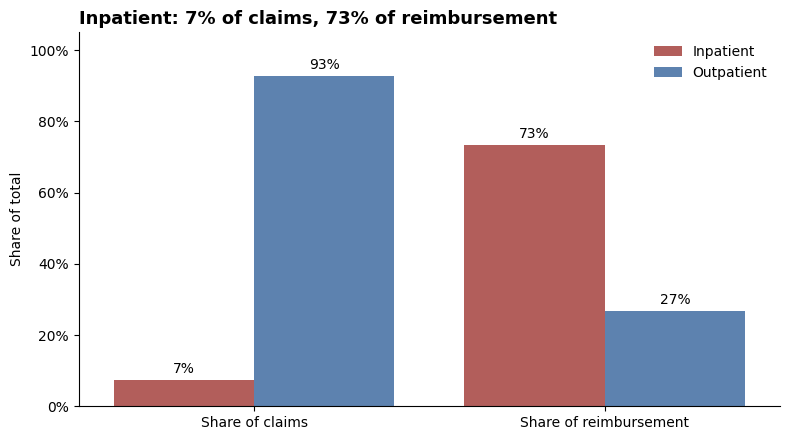

In [198]:
from matplotlib.ticker import PercentFormatter
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=plot_df, x='Metric', y='Share', hue='ClaimType',
            palette={'Inpatient': '#c0504d', 'Outpatient': '#4f81bd'}, ax=ax)

ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 1.05)
ax.set_xlabel('')
ax.set_ylabel('Share of total')
for container in ax.containers:
    ax.bar_label(container, fmt=lambda v: f'{v:.0%}', padding=3)

ip = summary.loc['IP']
ax.set_title(f"Inpatient: {ip['Share of claims']:.0%} of claims, "
             f"{ip['Share of reimbursement']:.0%} of reimbursement",
             loc='left', fontsize=13, fontweight='bold')
ax.legend(title='', frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

## Analysis 2 — IP vs OP: claim amount distribution (mean vs median; P50, P90, P99)
1. Outpatient is the more skewed population: the mean is 3.6 times the median (vs 1.4 for inpatient).
2. 90% of outpatient claims are under 700 dollars.
3. 90% of inpatient claims are $3,000 or more, and the top 1% exceed 57,000 dollars.
4. 7 outpatient records have reimbursed amount exceeding 20k dolloars, 5 out of 7 have providers that are flagged as potential fraud

In [199]:
summary2 = claims_w_bene[claims_w_bene['InscClaimAmtReimbursed']>0].groupby('ClaimType').agg(
    claim_count = ('ClaimID', 'count'),
    amount_mean=('InscClaimAmtReimbursed', 'mean'),
    amount_median=('InscClaimAmtReimbursed', lambda x:x.quantile(0.5)),
    amount_percentile_05=('InscClaimAmtReimbursed', lambda x:x.quantile(0.05)),
    amount_percentile_10=('InscClaimAmtReimbursed', lambda x:x.quantile(0.1)),
    amount_percentile_20=('InscClaimAmtReimbursed', lambda x:x.quantile(0.2)),
    amount_percentile_30=('InscClaimAmtReimbursed', lambda x:x.quantile(0.3)),
    amount_percentile_40=('InscClaimAmtReimbursed', lambda x:x.quantile(0.4)),
    amount_percentile_90=('InscClaimAmtReimbursed', lambda x:x.quantile(0.9)),
    amount_percentile_99=('InscClaimAmtReimbursed', lambda x:x.quantile(0.99)),
    amount_max=('InscClaimAmtReimbursed', lambda x:x.max()),
).reset_index()
summary2['mean-divide-median'] = summary2['amount_mean'] / summary2['amount_median']
summary2

,ClaimType,claim_count,amount_mean,amount_median,amount_percentile_05,amount_percentile_10,amount_percentile_20,amount_percentile_30,amount_percentile_40,amount_percentile_90,amount_percentile_99,amount_max,mean-divide-median
0,IP,39389,10365.762523,7000.0,3000.0,3000.0,4000.0,5000.0,6000.0,21000.0,57000.0,125000,1.480823
1,OP,498169,297.581985,80.0,10.0,20.0,30.0,50.0,60.0,700.0,3300.0,102500,3.719775


In [200]:
summary2[['ClaimType', 'claim_count', 'amount_mean', 'amount_median',
       'amount_percentile_10', 'amount_percentile_90',
       'amount_percentile_99', 'amount_max', 'mean-divide-median']]

,ClaimType,claim_count,amount_mean,amount_median,amount_percentile_10,amount_percentile_90,amount_percentile_99,amount_max,mean-divide-median
0,IP,39389,10365.762523,7000.0,3000.0,21000.0,57000.0,125000,1.480823
1,OP,498169,297.581985,80.0,20.0,700.0,3300.0,102500,3.719775


In [201]:
plot_df3 = claims_w_bene.loc[claims_w_bene['InscClaimAmtReimbursed']>0,['ClaimType','InscClaimAmtReimbursed']].copy()
plot_df3['ClaimType'] = plot_df3['ClaimType'].map({'IP': 'Inpatient', 'OP': 'Outpatient'})
plot_df3.head()

,ClaimType,InscClaimAmtReimbursed
0,Inpatient,26000
1,Inpatient,5000
2,Inpatient,5000
3,Inpatient,5000
4,Inpatient,10000


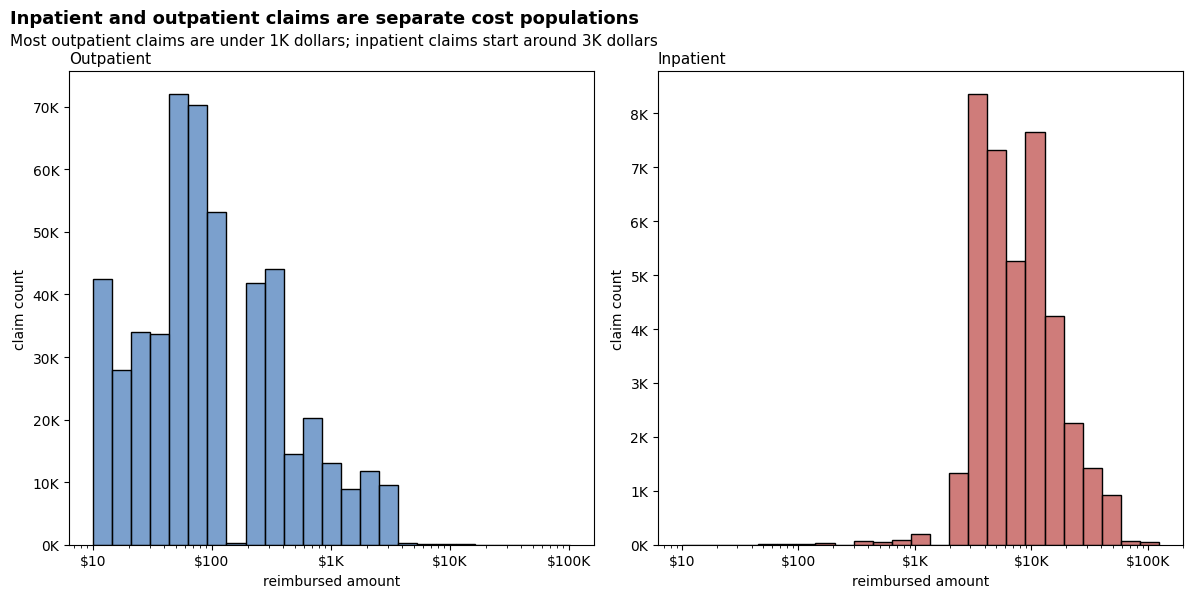

In [202]:
from matplotlib import ticker

fig, (ax1, ax2) = plt.subplots(1,2, figsize = (12,6))
sns.histplot(data = plot_df3[plot_df3['ClaimType'] == 'Outpatient'], x = 'InscClaimAmtReimbursed', bins = 25, log_scale = True, color='#4f81bd', ax=ax1)
sns.histplot(data = plot_df3[plot_df3['ClaimType'] == 'Inpatient'], x = 'InscClaimAmtReimbursed', bins = 25, log_scale = True, color='#c0504d', ax=ax2)

def dollars(v, pos):
    return f'${v/1000:,.0f}K' if v >=1000 else f'${v:.0f}'

def thousands(v, pos):
    return f'{v/1000:,.0f}K'

for ax, name in [(ax1, 'Outpatient'), (ax2, 'Inpatient')]:
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(dollars))
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(thousands))
    ax.set_title(name, loc = 'left', fontsize = 11)
    ax.set_ylabel('claim count')
    ax.set_xlabel('reimbursed amount')

title = 'Inpatient and outpatient claims are separate cost populations'
text = 'Most outpatient claims are under 1K dollars; inpatient claims start around 3K dollars'
fig.suptitle(title,x = 0.01, y = 0.99, ha = 'left', fontsize=13, fontweight='bold')
fig.text(x = 0.01, y = 0.93, s = text, ha = 'left', fontsize = 11)
plt.tight_layout()
plt.show()

## Finding: 7 outpatient records have reimbursed amount exceeding 20k dolloars
1. 7 outpatient claims (0.0014% of outpatient claims) exceed 20K dollars, about 6 times the outpatient P99 of 3,300 dollars. 
2. 5 of 7 (71%) come from providers flagged as potential fraud, roughly twice the 37% rate across all outpatient claims.
3. Together they were paid 637,290 dollars (0.43% of outpatient reimbursement), about 91K dollars per claim. The sample is small, but high-dollar outliers are a standard review trigger, and the result is consistent with it.

In [203]:
op_claims_above_20k = claims_w_bene.loc[(claims_w_bene['InscClaimAmtReimbursed']>20000 )& (claims_w_bene['ClaimType'] == 'OP')]
noted_amount = op_claims_above_20k['InscClaimAmtReimbursed'].sum()
noted_count = op_claims_above_20k['InscClaimAmtReimbursed'].shape[0]
total_op_amount = claims_w_bene[claims_w_bene['ClaimType']=='OP'].InscClaimAmtReimbursed.sum()
total_op_count = claims_w_bene[claims_w_bene['ClaimType']=='OP'].InscClaimAmtReimbursed.shape[0]
total_op_flagged_count = claims_w_bene[(claims_w_bene['ClaimType']=='OP') & (claims_w_bene['PotentialFraud'] == 'Yes')].InscClaimAmtReimbursed.shape[0]
print (f'Total paid: ${noted_amount:.0f}, {noted_amount/total_op_amount:.2%} of the total outpatient imbursed amount')
print (f'Total paid: {noted_count:.0f} records, {noted_count/total_op_count:.4%} of the total outpatient records')
print (f'The total flagged outpatient records is {total_op_flagged_count/total_op_count:.0%} of the total outpatient records')

Total paid: $637290, 0.43% of the total outpatient imbursed amount
Total paid: 7 records, 0.0014% of the total outpatient records
The total flagged outpatient records is 37% of the total outpatient records


In [204]:
op_claims_above_20k[['ClaimType','Provider','InscClaimAmtReimbursed','PotentialFraud']]

,ClaimType,Provider,InscClaimAmtReimbursed,PotentialFraud
49800,OP,PRV55172,102500,Yes
90909,OP,PRV51399,84460,Yes
273323,OP,PRV53114,85680,Yes
382146,OP,PRV55205,84660,No
389737,OP,PRV51119,95580,Yes
459298,OP,PRV56507,83160,No
546230,OP,PRV53461,101250,Yes


## Analysis 3 — Pareto (cost concentration)
Claims cost is highly concentrated: the top 1% of beneficiaries account for 16% of reimbursement, the top 5% for 44%, and the top 10% for 62% and the top 20% for 81%. A care management program focused on the top 5% would address over 40% of spending while reaching only 1 in 20 members.

In [205]:
reimbursed_by_bene = claims_w_bene.groupby('BeneID').agg(reimbursed_amt = ('InscClaimAmtReimbursed', 'sum')).reset_index().sort_values(by = 'reimbursed_amt', ascending = False)
reimbursed_by_bene['running_total_reimbursed_amt'] = reimbursed_by_bene.reimbursed_amt.cumsum()
reimbursed_by_bene['%running_total_reimbursed_amt_of_total'] = reimbursed_by_bene['running_total_reimbursed_amt'] / reimbursed_by_bene.reimbursed_amt.sum()
reimbursed_by_bene.index = range(1, len(reimbursed_by_bene) + 1)
reimbursed_by_bene['ranked_bene_by_top_percentile'] = reimbursed_by_bene.index / len(reimbursed_by_bene) 
reimbursed_by_bene

,BeneID,reimbursed_amt,running_total_reimbursed_amt,%running_total_reimbursed_amt_of_total,ranked_bene_by_top_percentile
1,BENE155688,260250,260250,0.000468,0.000007
2,BENE111157,241430,501680,0.000901,0.000014
3,BENE13669,227960,729640,0.001311,0.000022
4,BENE108968,207760,937400,0.001684,0.000029
5,BENE25318,188160,1125560,0.002022,0.000036
...,...,...,...,...,...
138552,BENE92799,0,556543140,1.000000,0.999971
138553,BENE127952,0,556543140,1.000000,0.999978
138554,BENE123703,0,556543140,1.000000,0.999986
138555,BENE123610,0,556543140,1.000000,0.999993


Top 1% of beneficiaries -> 15.6% of total cost
Top 5% of beneficiaries -> 43.6% of total cost
Top 10% of beneficiaries -> 62.0% of total cost
Top 20% of beneficiaries -> 81.4% of total cost


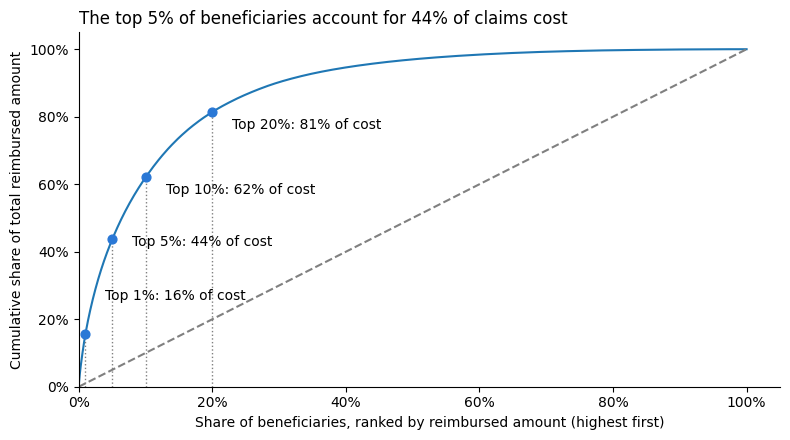

In [206]:
from matplotlib.ticker import PercentFormatter
import numpy as np
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.lineplot(data=reimbursed_by_bene, x='ranked_bene_by_top_percentile', y='%running_total_reimbursed_amt_of_total', ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color = 'grey')
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Share of beneficiaries, ranked by reimbursed amount (highest first)')
ax.set_ylabel('Cumulative share of total reimbursed amount')

y_values = np.asarray(reimbursed_by_bene['%running_total_reimbursed_amt_of_total'])
n = reimbursed_by_bene.shape[0]
label_offsets = {0.01: 0.1, 0.05: -0.02, 0.10: -0.05, 0.2: -0.05}
for p in [0.01, 0.05, 0.10, 0.2]:
    position = int(p * n) - 1     
    share = y_values[position]    
    ax.scatter(p, share, color='#2a78d6', s=40, zorder=3)
    ax.vlines(p, 0, share, colors='grey', linestyles=':', linewidth=1)
    ax.annotate(f"Top {p:.0%}: {share:.0%} of cost",
                xy=(p, share),
                xytext=(p + 0.03, share + label_offsets[p]),
                fontsize=10)

    print(f"Top {p:.0%} of beneficiaries -> {share:.1%} of total cost")
    
sns.despine()
ax.set_title(f'The top {0.05:.0%} of beneficiaries account for {y_values[int(0.05 * n) - 1]:.0%} of claims cost', loc = 'left')
plt.tight_layout()
plt.show()

## Analysis 4 — Chronic conditions
1. Median cost per beneficiary rises from 170 dollars with no chronic conditions to 8K with 10
2. The share of beneficiaries admitted at least once rises steadily with the number of chronic conditions, from about 3% with none to about 60% with 10. Since inpatient stays account for 73% of cost (Analysis 1), preventing avoidable admissions among members with many chronic conditions is the main cost lever.
3. Beneficiaries with kidney disease cost 4.8× more than those without
4. Inpatient spending is concentrated in the middle groups: beneficiaries with 5–7 chronic conditions account for 49% of inpatient reimbursement, mainly because these groups are both large (30% of beneficiaries) and frequently admitted (29–43%); the highest-rate groups (9+ conditions) account for only 8% because they contain few people.

### 4.1 Cost per beneficiary by number of chronic conditions (0–11); report median and mean
1. Median cost per beneficiary rises from 170 dollars with no chronic conditions to 8K with 10


In [207]:
reimbursed_by_bene_n_chronic_count = claims_w_bene.groupby(['BeneID', 'n_chronicCond']).agg(reimbursed_amt = ('InscClaimAmtReimbursed', 'sum')).reset_index().sort_values(by = 'reimbursed_amt', ascending = False)
reimbursed_by_bene_n_chronic_count.head(1)

,BeneID,n_chronicCond,reimbursed_amt
56422,BENE155688,5,260250


In [208]:
# Cost per beneficiary by number of chronic conditions (0, 1, 2, 3+); report median and mean
plot_df4 = reimbursed_by_bene_n_chronic_count.groupby('n_chronicCond').agg(
    mean_reimbursed_amt = ('reimbursed_amt', 'mean'),
    median_reimbursed_amt = ('reimbursed_amt', 'median'),
).reset_index()
plot_df4

,n_chronicCond,mean_reimbursed_amt,median_reimbursed_amt
0,0,665.932955,170.0
1,1,1253.323274,300.0
2,2,1924.336934,420.0
3,3,2787.323826,600.0
4,4,3689.429663,850.0
5,5,5016.033143,1265.0
6,6,6570.263176,2060.0
7,7,8036.849047,3000.0
8,8,9624.263408,4170.0
9,9,12031.816714,6180.0


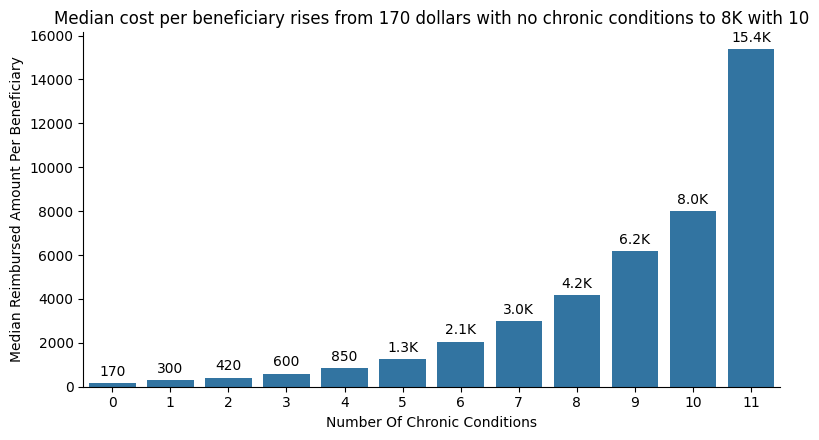

In [209]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=plot_df4, x='n_chronicCond', y='median_reimbursed_amt', ax=ax)
ax.set_xlabel('Number Of Chronic Conditions')
ax.set_ylabel('Median Reimbursed Amount Per Beneficiary')

for container in ax.containers:
    ax.bar_label(container, fmt=lambda v: f'{v/1000:.1f}K' if v>=1000 else f'{v:.0f}', padding=3)

sns.despine()
ax.set_title('Median cost per beneficiary rises from 170 dollars with no chronic conditions to 8K with 10')
plt.tight_layout()
plt.show()

### 4.2 Share hospitalised (any IP claim) by number of chronic conditions
1. The share of beneficiaries admitted at least once rises steadily with the number of chronic conditions, from about 3% with none to about 60% with 10. Since inpatient stays account for 73% of cost (Analysis 1), preventing avoidable admissions among members with many chronic conditions is the main cost lever.
2. Skip the 11-chronic-condition group because the group has only 71 people

In [210]:
cc_ip_df = claims_w_bene.groupby(['BeneID','n_chronicCond']).agg(has_admitted = ('ClaimType', 'min')).reset_index()
cc_ip_df.loc[cc_ip_df['has_admitted'] == 'IP', 'has_admitted'] = 1
cc_ip_df.loc[cc_ip_df['has_admitted'] == 'OP', 'has_admitted'] = 0
cc_ip_df

,BeneID,n_chronicCond,has_admitted
0,BENE100000,1,0
1,BENE100001,4,0
2,BENE100002,7,1
3,BENE100003,1,0
4,BENE100004,6,1
...,...,...,...
138551,BENE99994,3,0
138552,BENE99995,8,1
138553,BENE99997,6,0
138554,BENE99998,2,0


In [211]:
cc_ip_rate = cc_ip_df.groupby(['n_chronicCond']).agg(
    n_bene = ('BeneID', 'nunique'),
    n_bene_admitted = ('has_admitted', 'sum')
).reset_index()
cc_ip_rate['admission_rate'] = cc_ip_rate['n_bene_admitted'] / cc_ip_rate['n_bene']
cc_ip_rate

,n_chronicCond,n_bene,n_bene_admitted,admission_rate
0,0,11276,298,0.026428
1,1,16237,1092,0.067254
2,2,19440,2261,0.116307
3,3,20335,3490,0.171625
4,4,20146,4562,0.226447
5,5,17500,5147,0.294114
6,6,14363,5328,0.370953
7,7,10235,4367,0.426673
8,8,5892,2903,0.492702
9,9,2477,1424,0.574889


In [212]:
cc_ip_rate.n_bene_admitted.sum()

31289

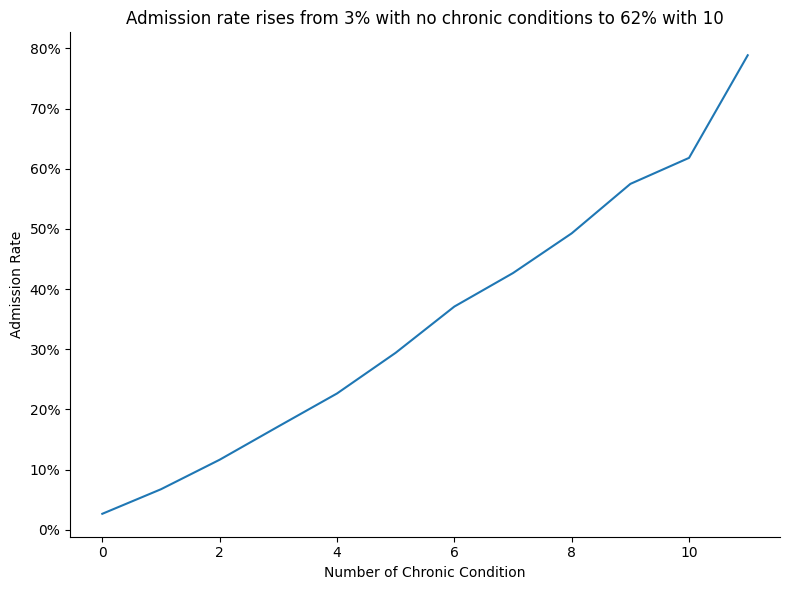

In [213]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.lineplot(data=cc_ip_rate, y='admission_rate', x='n_chronicCond', ax=ax)
ax.set_ylabel('Admission Rate')
ax.set_xlabel('Number of Chronic Condition')
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

sns.despine()
ax.set_title('Admission rate rises from 3% with no chronic conditions to 62% with 10')
plt.tight_layout()
plt.show()

### 4.3 Most expensive single conditions: median cost per beneficiary with vs without each condition
1. Beneficiaries with kidney disease cost 4.8× more than those without
2. Noted that chronic conditions often occur together, and hence these ratios reflect each condition plus its typical co-occurring conditions, not the condition alone.

In [214]:
reimbursed_by_bene.head(3)

,BeneID,reimbursed_amt,running_total_reimbursed_amt,%running_total_reimbursed_amt_of_total,ranked_bene_by_top_percentile
1,BENE155688,260250,260250,0.000468,0.000007
2,BENE111157,241430,501680,0.000901,0.000014
3,BENE13669,227960,729640,0.001311,0.000022


In [215]:
chronic_cols = claims_w_bene.columns[claims_w_bene.columns.str.startswith('ChronicCond')]
chronic_cols

Index(['ChronicCond_Alzheimer', 'ChronicCond_Heartfailure',
       'ChronicCond_KidneyDisease', 'ChronicCond_Cancer',
       'ChronicCond_ObstrPulmonary', 'ChronicCond_Depression',
       'ChronicCond_Diabetes', 'ChronicCond_IschemicHeart',
       'ChronicCond_Osteoporasis', 'ChronicCond_rheumatoidarthritis',
       'ChronicCond_stroke'],
      dtype='object')

In [216]:
bene_w_cc = beneficiary[['BeneID'] + list(chronic_cols)].merge(reimbursed_by_bene[['BeneID', 'reimbursed_amt']], on='BeneID', how='left')
bene_w_cc['reimbursed_amt'] = bene_w_cc['reimbursed_amt'].fillna(0)
bene_w_cc

,BeneID,ChronicCond_Alzheimer,ChronicCond_Heartfailure,ChronicCond_KidneyDisease,ChronicCond_Cancer,ChronicCond_ObstrPulmonary,ChronicCond_Depression,ChronicCond_Diabetes,ChronicCond_IschemicHeart,ChronicCond_Osteoporasis,ChronicCond_rheumatoidarthritis,ChronicCond_stroke,reimbursed_amt
0,BENE11001,1,0,1,0,0,1,1,1,0,1,1,36000
1,BENE11002,0,0,0,0,0,0,0,0,0,0,0,30
2,BENE11003,1,0,0,0,0,0,0,1,0,0,0,90
3,BENE11004,1,1,0,0,0,0,1,1,1,1,0,1810
4,BENE11005,0,0,0,0,1,0,1,0,0,0,0,1790
...,...,...,...,...,...,...,...,...,...,...,...,...,...
138551,BENE159194,1,0,0,0,0,0,0,0,0,0,0,400
138552,BENE159195,1,0,0,0,0,0,1,0,0,0,0,880
138553,BENE159196,0,1,1,1,0,1,1,1,0,0,0,3240
138554,BENE159197,1,1,0,0,0,0,0,1,0,0,0,150


In [217]:
results = []
for col in chronic_cols:
    medians = bene_w_cc.groupby(col)['reimbursed_amt'].median()   # 索引 0 = 没有，1 = 有
    results.append({
        'condition': col.replace('ChronicCond_', ''),
        'median_with': medians[1],
        'median_without': medians[0],
        'bene_count_with': (bene_w_cc[col] == 1).sum(),
    })

cc_summary = pd.DataFrame(results)
cc_summary['ratio'] = cc_summary['median_with'] / cc_summary['median_without']
cc_summary = cc_summary.sort_values('ratio', ascending=False).reset_index(drop=True)

cc_summary

,condition,median_with,median_without,bene_count_with,ratio
0,KidneyDisease,2390.0,500.0,43279,4.780000
1,ObstrPulmonary,2280.0,550.0,32859,4.145455
2,stroke,2500.0,670.0,10954,3.731343
3,Diabetes,1150.0,400.0,83391,2.875000
4,Heartfailure,1290.0,450.0,68402,2.866667
5,IschemicHeart,1060.0,370.0,93644,2.864865
6,Cancer,1780.0,650.0,16621,2.738462
7,Alzheimer,1320.0,560.0,46026,2.357143
8,Depression,1270.0,540.0,49260,2.351852
9,rheumatoidarthritis,1250.0,600.0,35584,2.083333


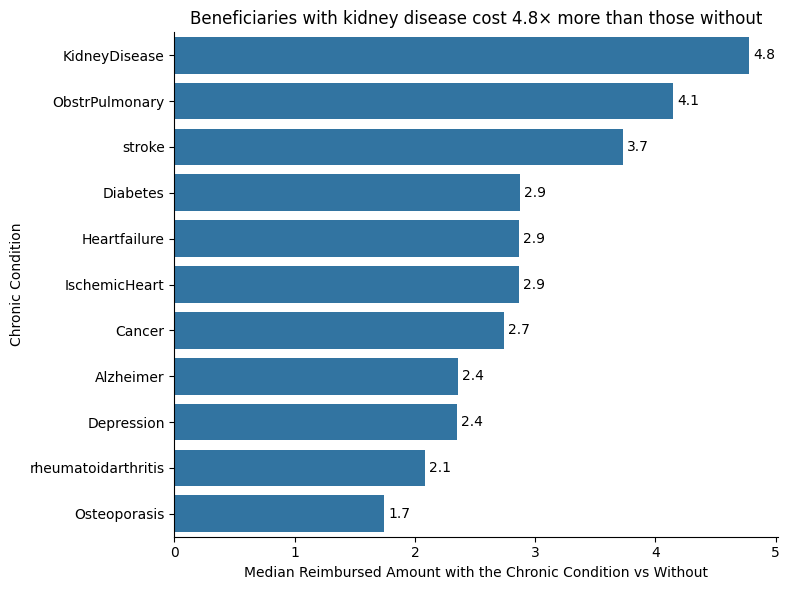

In [218]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=cc_summary, y='condition', x='ratio', ax=ax, orient = 'h')
ax.set_ylabel('Chronic Condition')
ax.set_xlabel('Median Reimbursed Amount with the Chronic Condition vs Without')

for container in ax.containers:
    ax.bar_label(container, fmt=lambda v: f'{v:.1f}', padding=3)

sns.despine()
ax.set_title('Beneficiaries with kidney disease cost 4.8× more than those without')
plt.tight_layout()
plt.show()

### 4.4 Share of inpatient spending by number of chronic conditions
1. Inpatient spending is concentrated in the middle groups: beneficiaries with 5–7 chronic conditions account for 49% of inpatient reimbursement, mainly because these groups are both large (30% of beneficiaries) and frequently admitted (29–43%); the highest-rate groups (9+ conditions) account for only 8% because they contain few people.


In [219]:
ip_reimbursed_by_cc = claims_w_bene[claims_w_bene['ClaimType'] == 'IP'].groupby('n_chronicCond').agg(reimbursed_amt = ('InscClaimAmtReimbursed', 'sum')).reset_index()
ip_reimbursed_by_cc['reimbursed_amt%'] = ip_reimbursed_by_cc['reimbursed_amt'] / ip_reimbursed_by_cc['reimbursed_amt'].sum()
ip_reimbursed_by_cc

,n_chronicCond,reimbursed_amt,reimbursed_amt%
0,0,2703500,0.006621
1,1,10852720,0.026580
2,2,23552930,0.057686
3,3,39307930,0.096273
4,4,52835630,0.129405
5,5,64251170,0.157364
6,6,71648510,0.175481
7,7,64620800,0.158269
8,8,45631850,0.111761
9,9,24839630,0.060837


## Analysis 5 — Fraud vs non-fraud providers
1. Flagged providers are much larger than other providers: a median of 156 vs 27 claims (5.8×), 117 vs 22 beneficiaries (5.3×), and 373K vs 15K reimbursed in dollar (25×).
2. They are also inpatient-heavy (median inpatient share of cost 91% vs 0%).
3. Billing intensity differs much less: claims per beneficiary are 1.19 vs 1.08 (1.1×) and claims per physician 4.6 vs 3.0 (1.6×).
4. Most of the difference reflects provider size and type, so review rules should compare providers against peers of similar size and type rather than flag large inpatient providers outright.

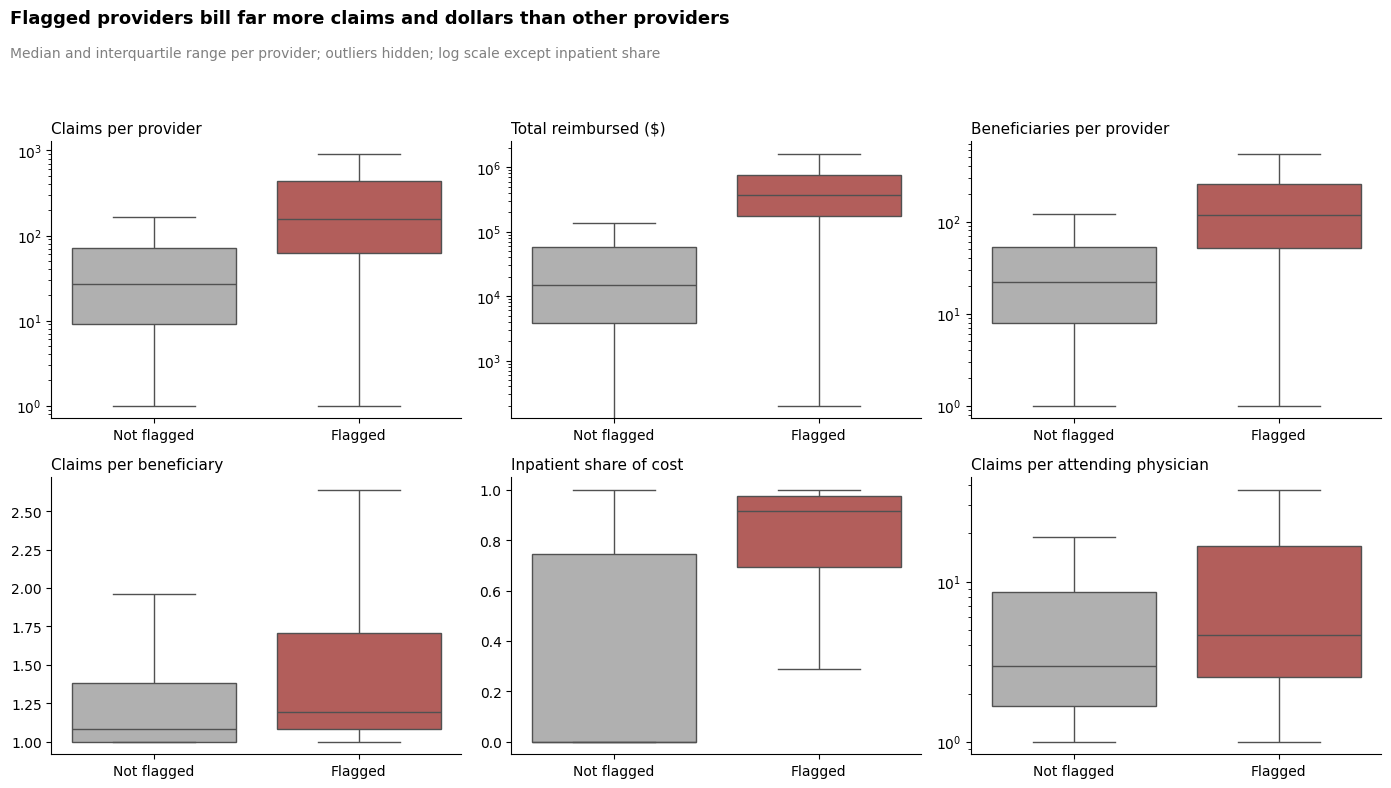

,Not flagged,Flagged,Flagged ÷ not flagged
Claims per provider,27.00,155.50,5.76
Total reimbursed ($),15055.00,373450.00,24.81
Beneficiaries per provider,22.00,117.00,5.32
Claims per beneficiary,1.08,1.19,1.10
Inpatient share of cost,0.00,0.91,NaN
Claims per attending physician,2.96,4.63,1.56


In [220]:
import matplotlib.pyplot as plt
import seaborn as sns

# Features to compare, with readable panel titles
features = {
    'claim_count': 'Claims per provider',
    'total_amt_reimbursed': 'Total reimbursed ($)',
    'beneficiary_count': 'Beneficiaries per provider',
    'claim_per_bene': 'Claims per beneficiary',
    'ip_cost_of_all': 'Inpatient share of cost',
    'claim_per_physician': 'Claims per attending physician',
}
log_features = {'claim_count', 'total_amt_reimbursed', 'beneficiary_count', 'claim_per_physician'}
fraud_colors = {'No': '#b0b0b0', 'Yes': '#c0504d'}

# Drop infinite values (providers with 0 attending physicians) before plotting
plot_provider = provider.replace([np.inf, -np.inf], np.nan)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, (col, label) in zip(axes.flatten(), features.items()):
    sns.boxplot(data=plot_provider, x='PotentialFraud', y=col,
                order=['No', 'Yes'], hue='PotentialFraud', palette=fraud_colors,
                showfliers=False, legend=False, ax=ax)
    if col in log_features:
        ax.set_yscale('log')
    ax.set_title(label, loc='left', fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticks([0, 1], ['Not flagged', 'Flagged'])
    sns.despine(ax=ax)

fig.suptitle('Flagged providers bill far more claims and dollars than other providers',
             x=0.01, ha='left', fontsize=13, fontweight='bold')
fig.text(0.01, 0.92, 'Median and interquartile range per provider; outliers hidden; log scale except inpatient share',
         ha='left', fontsize=10, color='grey')
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

# Median table: exact numbers for the "so what"
medians = plot_provider.groupby('PotentialFraud')[list(features)].median().T
medians.columns = ['Not flagged', 'Flagged']
medians['Flagged ÷ not flagged'] = medians['Flagged'] / medians['Not flagged']
medians['Flagged ÷ not flagged'] = medians['Flagged ÷ not flagged'].replace([np.inf, -np.inf], np.nan)
medians.index = [features[c] for c in medians.index]
medians.round(2)